### Лабораторная работа №9 "Численное решение дифференциальных уравнений"

#### Задание №1
Дано уравнение 
$$\varepsilon\frac{ds}{dt}+s=0,$$     $$t\in[0,1],$$     $$s(0)=1,$$    $$\varepsilon\ll1.$$

Необходимо найти:
1. Точное решение уравнения;
2. Построить график точного решения при $\varepsilon=0.1$ и $\varepsilon=0.01$;
3. Численно решить методом Эйлера уравнение для $\varepsilon=0.01$ с шагом $\Delta t=0.02$ и шагом $\Delta t=0.002$;
4. Построить графики для численных решений.

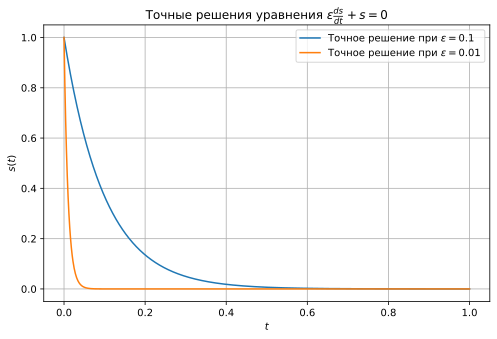

In [2]:
# Пример вывода 2х графиков на одном рисунке
import numpy as np
import matplotlib.pyplot as plt
import math
%matplotlib inline 
#графики встраиваются в блокнот;
%config InlineBackend.figure_format = 'svg' #векторный формат #векторный формат

def exact_solution(t, eps):
    """Аналитическое решение: s(t) = exp(-t / eps)"""
    return np.exp(-t / eps)

eps1 = 0.1
eps2 = 0.01

t = np.linspace(0, 1, 1000)  # увеличим разрешение для гладкости
s1 = exact_solution(t, eps1)
s2 = exact_solution(t, eps2)

plt.figure(figsize=(8, 5))
plt.plot(t, s1, label=r'Точное решение при $\varepsilon = 0.1$')
plt.plot(t, s2, label=r'Точное решение при $\varepsilon = 0.01$')
plt.grid(True)
plt.legend()
plt.xlabel(r'$t$')
plt.ylabel(r'$s(t)$')
plt.title('Точные решения уравнения $\\varepsilon \\frac{ds}{dt} + s = 0$')
plt.show()

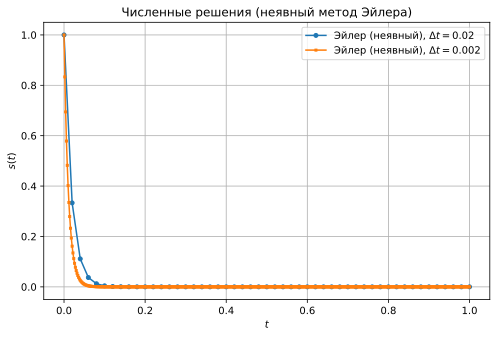

In [5]:
def euler_solve(t0, t1, y0, eps, n):
    t, h = np.linspace(t0, t1, n, retstep=True)
    s = [y0]
    s_n = y0
    for _ in range(1, n):
        s_n = s_n / (1 + h / eps)  # неявный Эйлер
        s.append(s_n)
    return t, np.array(s)

t0, t1 = 0, 1
y0 = 1
eps = 0.01
dt1 = 0.02
dt2 = 0.002

n1 = int((t1 - t0) / dt1) + 1
n2 = int((t1 - t0) / dt2) + 1

t1_e, s1_e = euler_solve(t0, t1, y0, eps, n1)
t2_e, s2_e = euler_solve(t0, t1, y0, eps, n2)

plt.figure(figsize=(8, 5))
plt.plot(t1_e, s1_e, 'o-', label=r'Эйлер (неявный), $\Delta t = 0.02$', markersize=4)
plt.plot(t2_e, s2_e, 's-', label=r'Эйлер (неявный), $\Delta t = 0.002$', markersize=2)
plt.grid(True)
plt.legend()
plt.xlabel(r'$t$')
plt.ylabel(r'$s(t)$')
plt.title('Численные решения (неявный метод Эйлера)')
plt.show()

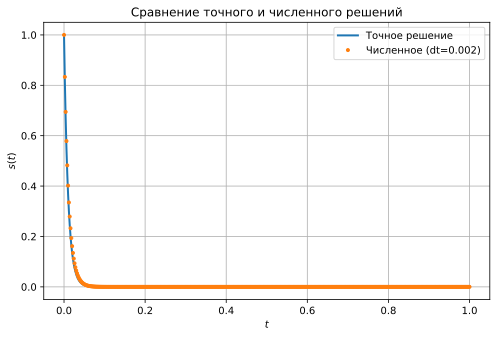

In [6]:
#сравнение нормальных решений
eps = 0.01
dt = 0.002
n = int(1 / dt) + 1

t_num, s_num = euler_solve(0, 1, 1, eps, n)
t_exact = np.linspace(0, 1, 1000)
s_exact = exact_solution(t_exact, eps)

plt.figure(figsize=(8, 5))
plt.plot(t_exact, s_exact, '-', label='Точное решение', linewidth=2)
plt.plot(t_num, s_num, 'o', label=f'Численное (dt={dt})', markersize=3)
plt.grid(True)
plt.legend()
plt.xlabel(r'$t$')
plt.ylabel(r'$s(t)$')
plt.title('Сравнение точного и численного решений')
plt.show()

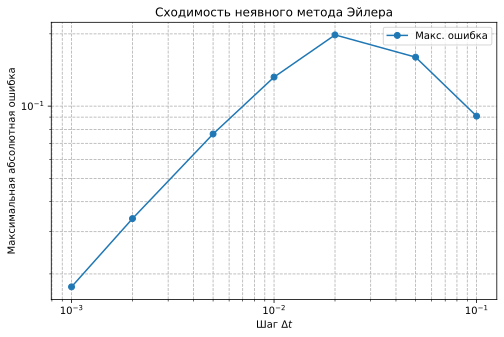

Порядок сходимости: 0.41 (ожидается ~1)


In [7]:
# Оценка ошибки аппроксимации
errors = []
dts = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001]

for dt in dts:
    n = int(1 / dt) + 1
    t_num, s_num = euler_solve(0, 1, 1, eps, n)
    s_exact_interp = exact_solution(t_num, eps)
    err = np.max(np.abs(s_num - s_exact_interp))
    errors.append(err)

plt.figure(figsize=(8, 5))
plt.loglog(dts, errors, 'o-', label='Макс. ошибка')
plt.grid(True, which="both", ls="--")
plt.xlabel(r'Шаг $\Delta t$')
plt.ylabel('Максимальная абсолютная ошибка')
plt.title('Сходимость неявного метода Эйлера')
plt.legend()
plt.show()

# Вывод порядка сходимости
from scipy.stats import linregress
log_dt = np.log(dts)
log_err = np.log(errors)
slope, _, _, _, _ = linregress(log_dt, log_err)
print(f"Порядок сходимости: {slope:.2f} (ожидается ~1)")

#### Задание №2
1. Разобраться с примером (данным ниже) динамики материальной точки в поле силы тяжести и с сопротивлением при движении (брошенный мяч). Система интегрируется методом Эйлера.
2. Изменить и дополнить пример наличием силы тяги (с произвольным профилем, задается студентом).
4. Решить систему ОДУ при помощи модуля scipy.integrate.ode (см. [официальную справку](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.ode.html) ). Изучить метод интегрирования, который реализован в библиотеке. В качестве момента остановки интегрирования взять момент "пдаения" мяча на "землю".
5. Построить график получившийся траектории.
6. Построить профиль тяги (от времени).

In [ ]:
import numpy as np
from math import * #импортируем все функции

#константы для вычислений

#для перевода радиан в градусы
grad = pi/180 

g = 9.81 # -_-

# плотность выоздуха
ro = 1.240 

#скорость звука
a = 340

# тяга включена 0.5 сек, потом выключена.
def thrust_profile(t):
    """Возвращает величину тяги P в зависимости от времени."""
    if t <= 0.5:
        return 500.0  # Ньютонов
    else:
        return 0.0

\begin{equation*}
\overrightarrow{Y} = 
\begin{pmatrix}
Y[0] \\
Y[1]\\
Y[2]\\
Y[3]
\end{pmatrix} 
 = 
\begin{pmatrix}
x \\
y \\
V_x \\
V_y
\end{pmatrix}
\end{equation*}


\begin{equation*}
\frac{d\overrightarrow{Y}}{dt} = \overrightarrow{f}(t,\overrightarrow{Y}) =
\begin{pmatrix}
f[0] \\
f[1] \\
f[2] \\
f[3]
\end{pmatrix} 
=
\begin{pmatrix}
\frac{dY[0]}{dt}\\
\frac{dY[1]}{dt}\\
\frac{dY[1]}{dt}\\
\frac{dY[1]}{dt}
\end{pmatrix}
=
\begin{pmatrix}
V_x \\
V_y \\
\frac{dV_x}{dt} \\
\frac{dV_y}{dt}
\end{pmatrix}
\end{equation*}

In [9]:
#начальное положение м.т.
x_0 = 0 
y_0 = 0

#начальная скорость
V_0 = 100

#начальнчй угол
thetta_0 = 30

#масса
mass = 30

#площадь миделя
S_m = pi*0.1**2/4

#тяга
P = 0

In [16]:
# Н.У
Y_0 = np.array([
    x_0,
    y_0,
    V_0 * cos(thetta_0 * grad),
    V_0 * sin(thetta_0 * grad)
])
Y_0

array([ 0.        ,  0.        , 86.60254038, 50.        ])

In [22]:
def C_x(M):
    """
    Коэффициент лобового сопротивления для сферического тела
    в зависимости от числа Маха.
    """
    M = abs(M)  # на всякий случай
    if M < 0.8:
        return 0.45
    elif M < 1.0:
        # Линейный рост от 0.45 до 0.95
        return 0.45 + (0.95 - 0.45) * (M - 0.8) / (1.0 - 0.8)
    elif M < 1.2:
        # Пик в районе M=1.0–1.1, затем спад
        return 0.95 - (0.95 - 0.75) * (M - 1.0) / (1.2 - 1.0)
    elif M < 3.0:
        # Постепенное уменьшение до 0.25
        return 0.75 - (0.75 - 0.25) * (M - 1.2) / (3.0 - 1.2)
    else:
        # При очень высоких M — стабилизация
        return 0.25

In [19]:
# Переписать немного функцию правых частей dY/dt
def f(t, Y):
    x, y, Vx, Vy = Y
    V = sqrt(Vx**2 + Vy**2)
    if V == 0:
        C = 0
    else:
        M = V / a  # число Маха
        C = C_x(M)
    
    # Сила сопротивления (против скорости)
    F_drag = 0.5 * ro * V**2 * S_m * C
    Fx_drag = -F_drag * (Vx / V) if V != 0 else 0
    Fy_drag = -F_drag * (Vy / V) if V != 0 else 0

    # Тяга
    P = thrust_profile(t)
    # Предположим, что тяга направлена по скорости (или по начальному углу — уточните!)
    # Вариант: тяга по направлению скорости
    if V != 0:
        Px = P * (Vx / V)
        Py = P * (Vy / V)
    else:
        # Если скорость = 0, направляем по начальному углу
        Px = P * cos(theta_0 * grad)
        Py = P * sin(theta_0 * grad)

    # Ускорения
    ax = (Px + Fx_drag) / mass
    ay = (Py + Fy_drag) / mass - g

    return np.array([Vx, Vy, ax, ay])

In [20]:
def euler(t0, t1, y0, f, n_points):
    t, h = np.linspace(t0, t1, n_points, retstep=True)
    y = np.empty((n_points, len(y0)))
    y[0] = y0
    for i in range(1, n_points):
        y[i] = y[i-1] + h * f(t[i-1], y[i-1])
    return y, t

In [23]:
y_euler, t_euler = euler(0, 7, Y_0, f, 100)

In [24]:
import matplotlib.pyplot as plt
%matplotlib inline 
#графики встраиваются в блокнот;
%config InlineBackend.figure_format = 'svg' #векторный формат #векторный формат

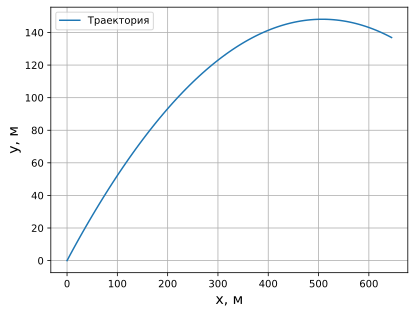

In [26]:
xs = y_euler[:,0]
ys = y_euler[:,1]
plt.plot(xs, ys, label='Траектория');
plt.grid()
plt.xlabel('x, м', fontsize=14)
plt.ylabel('y, м', fontsize=14)
plt.legend(loc='best');

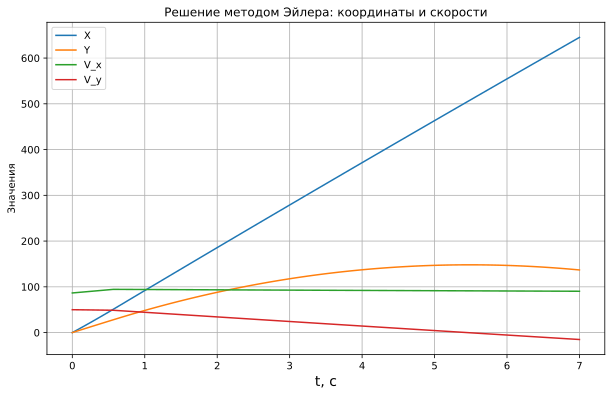

In [ ]:
ts = t_euler
xs = y_euler[:, 0]
ys = y_euler[:, 1]
Vxs = y_euler[:, 2]
Vys = y_euler[:, 3]

plt.figure(figsize=(10, 6))
plt.plot(ts, xs, label='X')
plt.plot(ts, ys, label='Y')
plt.plot(ts, Vxs, label='V_x')
plt.plot(ts, Vys, label='V_y')

plt.grid()  # сетка
plt.xlabel('t, c', fontsize=14)
plt.ylabel('Значения')
plt.legend(loc='best')
plt.title('Решение методом Эйлера: координаты и скорости')
plt.show()

In [34]:
from scipy import integrate as integ

t0 = 0
t1 = 20  # дадим больше времени
n = 2000

ODE = integ.ode(f)
ODE.set_integrator('dopri5', atol=1e-8, rtol=1e-6)
ODE.set_initial_value(Y_0, t0)

t_vals = [t0]
Y_vals = [Y_0]

while ODE.successful() and ODE.y[1] >= 0 and ODE.t < t1:
    ODE.integrate(ODE.t + 0.01)  # шаг интегратора адаптивный, но двигаемся мелко
    t_vals.append(ODE.t)
    Y_vals.append(ODE.y.copy())

Y_vals = np.array(Y_vals)
t_vals = np.array(t_vals)

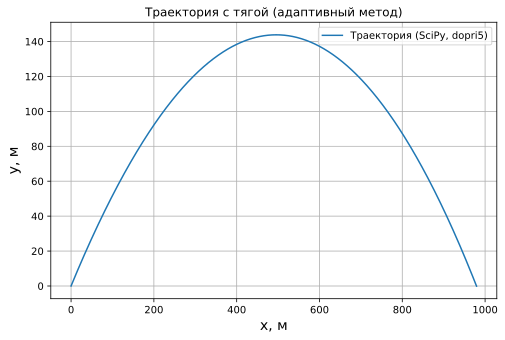

In [ ]:
xs = Y_vals[:, 0]
ys = Y_vals[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(xs, ys, label='Траектория (SciPy, dopri5)')
plt.grid()
plt.xlabel('x, м', fontsize=14)
plt.ylabel('y, м', fontsize=14)
plt.legend(loc='best')
plt.title('Траектория с тягой (адаптивный метод)')
plt.show()

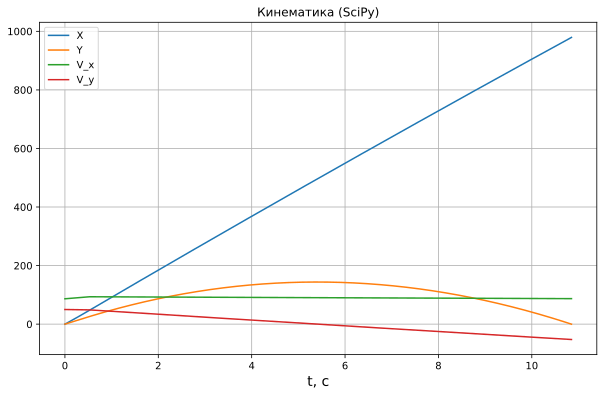

In [37]:
plt.figure(figsize=(10, 6))
plt.plot(t_vals, xs, label='X')
plt.plot(t_vals, ys, label='Y')
plt.plot(t_vals, Y_vals[:, 2], label='V_x')
plt.plot(t_vals, Y_vals[:, 3], label='V_y')
plt.grid()
plt.xlabel('t, c', fontsize=14)
plt.legend(loc='best')
plt.title('Кинематика (SciPy)')
plt.show()

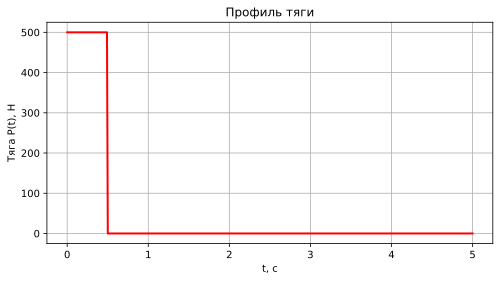

In [39]:
t_plot = np.linspace(0, 5, 500)
P_plot = [thrust_profile(t) for t in t_plot]

plt.figure(figsize=(8, 4))
plt.plot(t_plot, P_plot, 'r-', linewidth=2)
plt.grid()
plt.xlabel('t, c')
plt.ylabel('Тяга P(t), Н')
plt.title('Профиль тяги')
plt.show()